# Regularized and Polynomial Regression

## Lesson objectives

- Understand why linear models may fail because of overfitting, multicollinearity, or nonlinearity.
- Formulate Ridge, Lasso, and Elastic Net as penalized least squares.
- Use `PolynomialFeatures` to model nonlinear relationships through feature expansion.
- Implement everything in `scikit-learn` using `Pipeline` and cross-validation.
- Apply these methods to real public data from a combined-cycle power plant.

In [1]:
from pathlib import Path
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA_DIR = Path("data")
FIG_DIR = Path("figures_regularized_polynomial_regression")
FIG_DIR.mkdir(exist_ok=True)

CCPP_FILE = DATA_DIR / "CCPP.zip"
AIRPASSENGERS_FILE = DATA_DIR / "AirPassengers.csv"

missing = [str(p) for p in [CCPP_FILE, AIRPASSENGERS_FILE] if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Files not found. Place the notebook at the project root and the data in data/: "
        + ", ".join(missing)
    )


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

## When least squares becomes fragile

- **Overfitting:** too many degrees of freedom for too little data.
- **Multicollinearity:** nearly redundant inputs make coefficients unstable; small changes in the data can substantially change them.
- **Scale:** variables in different units distort the penalty.
- **Nonlinearity:** a straight line may not describe the true relationship well.

Examples in Electrical Engineering:

- temperature sensors at nearby locations;
- current, power, and accumulated energy in the same system;
- an experiment with few observations and many extracted features.

## Linear model as a starting point

For $n$ samples and $p$ features:

$$
X \in \mathbb{R}^{n \times p}, \qquad y \in \mathbb{R}^n,
$$

$$
\hat{y}_i = \beta_0 + \sum_{j=1}^{p}\beta_j x_{ij}.
$$

In vector form, with $\boldsymbol{\beta}=[\beta_1,\ldots,\beta_p]^\top$:

$$
\hat{y}=\beta_0\mathbf{1}+X\boldsymbol{\beta}.
$$

Unregularized cost:

$$
J_{OLS}(\beta_0,\boldsymbol{\beta}) =
\frac{1}{n}\sum_{i=1}^{n}\left(y_i-\beta_0-x_i^\top\boldsymbol{\beta}\right)^2.
$$

If coefficients must be very large to explain noise or redundancy, predictions tend to vary excessively outside the training data.

## Regularization: penalizing complexity

Ridge, Lasso, and Elastic Net start with squared error and add penalties on the coefficients.

**Ridge:**

$$
J_{Ridge}(\beta_0,\boldsymbol{\beta}) =
\frac{1}{n}\sum_{i=1}^{n}\left(y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}\right)^2
+\alpha\sum_{j=1}^{p}\beta_j^2.
$$

**Lasso:**

$$
J_{Lasso}(\beta_0,\boldsymbol{\beta}) =
\frac{1}{n}\sum_{i=1}^{n}\left(y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}\right)^2
+\alpha\sum_{j=1}^{p}|\beta_j|.
$$

**ElasticNet:**

$$
J_{EN}(\beta_0,\boldsymbol{\beta}) =
\frac{1}{n}\sum_{i=1}^{n}\left(y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}\right)^2
+\alpha\left[\rho\sum_{j=1}^{p}|\beta_j|+(1-\rho)\sum_{j=1}^{p}\beta_j^2\right].
$$

- $\alpha$ controls regularization strength.
- Ridge = L2; Lasso = L1; Elastic Net = L1 + L2.
- $\rho$ is the Elastic Net `l1_ratio`.
- We penalize $\boldsymbol{\beta}$; the intercept $\beta_0$ is not penalized.
- In `scikit-learn`, multiplicative constants change the numerical scale of $\alpha$.

## Safe implementation with `Pipeline`

Use `Pipeline` to safely implement preprocessing and a model. Scaling is fitted only on the training portion of each cross-validation split, preventing test-data leakage into training.

```python
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet

preprocess = ColumnTransformer([
    ("num", StandardScaler(), continuous_cols),
    ("cat", OneHotEncoder(drop="first"), categorical_cols)
])

ridge = Pipeline([
    ("preprocess", preprocess),
    ("model", Ridge(alpha=10.0))
])

ridge.fit(X_train, y_train)
y_pred = ridge.predict(X_test)
```

## How to read the `Pipeline`

`ColumnTransformer` applies different transformations to groups of columns.

- Continuous variables pass through `StandardScaler`: zero mean and unit standard deviation.
- Categorical variables pass through `OneHotEncoder`: each category becomes a 0/1 column.
- `Pipeline`: the transformation learned on the training set is applied to the test set.

Example using `load_type`:

| load_type | R without drop | L without drop | NL without drop | L with `drop="first"` | NL with `drop="first"` |
|---|---:|---:|---:|---:|---:|
| resistive | 1 | 0 | 0 | 0 | 0 |
| inductive | 0 | 1 | 0 | 1 | 0 |
| nonlinear | 0 | 0 | 1 | 0 | 1 |

With an intercept, keeping R, L, and NL creates perfect redundancy:

$$
R + L + NL = 1.
$$

Resistive load becomes the reference; the L and NL coefficients measure differences relative to it.

## Ridge: controlling unstable coefficients

Ridge uses an L2 penalty:

$$
\|\boldsymbol{\beta}\|_2^2=\sum_{j=1}^{p}\beta_j^2.
$$

- Penalizes large coefficients quadratically.
- Shrinks all coefficients but usually does not set them to zero.
- Works well when variables are correlated to some extent and all carry useful signal.

Parameters can be estimated by:

$$
\hat{\boldsymbol{\beta}}_{Ridge} = (X^\top X + n\alpha I)^{-1}X^\top y.
$$

## Lasso: regularization and feature selection

Lasso uses an L1 penalty:

$$
\|\boldsymbol{\beta}\|_1=\sum_{j=1}^{p}|\beta_j|.
$$

- Penalizes the absolute values of coefficients.
- Can set coefficients to zero, producing a sparser model.
- Useful when there are many candidate features and only a few are truly relevant.
- Caution: with highly correlated variables, Lasso may select one and discard another that is nearly equivalent.
- Sparsity increases as the penalty grows; choose the final $\alpha$ using validation.

## Elastic Net: a practical compromise

- Combines L1 and L2 penalties.
- Retains Lasso’s ability to select features.
- The L2 component improves stability among groups of correlated features.
- Main parameters: `alpha` and `l1_ratio`.

Rule of thumb: use Elastic Net when you expect sparsity but sensors/features appear in correlated groups.

## Case study: combined-cycle power plant

Dataset: **Combined Cycle Power Plant**, UCI Machine Learning Repository.

- 9,568 real hourly observations from a thermal power plant.
- Features: ambient temperature, exhaust vacuum, ambient pressure, and relative humidity.
- Target: net electrical power generated by the plant, in MW.
- Task: predict net generation from operating and ambient conditions.
- A supervised static regression problem.

In [2]:
def load_power_plant_data(path=CCPP_FILE):
    rename = {
        "AT": "ambient_temperature",
        "V": "exhaust_vacuum",
        "AP": "ambient_pressure",
        "RH": "relative_humidity",
        "PE": "net_power_output",
    }
    with zipfile.ZipFile(path) as archive:
        with archive.open("CCPP/Folds5x2_pp.xlsx") as handle:
            return pd.read_excel(handle).rename(columns=rename)

power = load_power_plant_data()
print(f"Dataset dimensions: {power.shape[0]} rows and {power.shape[1]} columns")

Dataset dimensions: 9568 rows and 5 columns


## What do the data already indicate?

Temperature and vacuum are strongly negatively correlated with net power and are also correlated with each other. The matrix guides initial feature selection and flags multicollinearity.

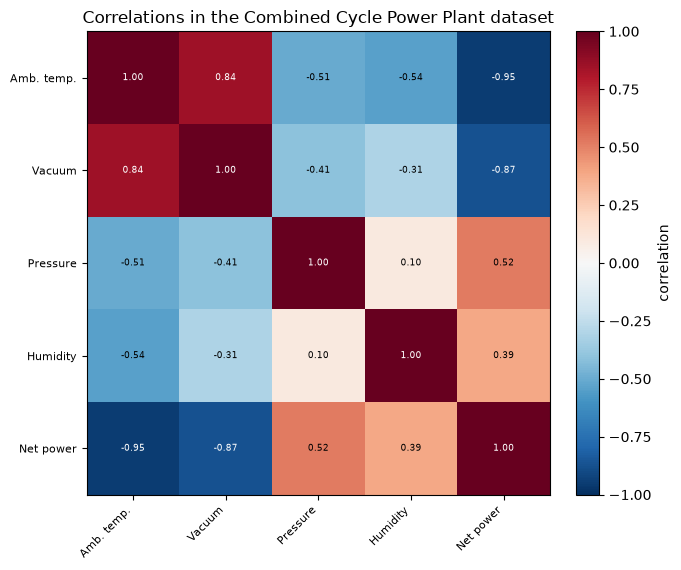

In [3]:
continuous_cols = [
    "ambient_temperature",
    "exhaust_vacuum",
    "ambient_pressure",
    "relative_humidity",
]
categorical_cols = []
feature_cols = continuous_cols + categorical_cols
target_col = "net_power_output"

corr = power[continuous_cols + [target_col]].corr(numeric_only=True)
labels = ["Amb. temp.", "Vacuum", "Pressure", "Humidity", "Net power"]

fig, ax = plt.subplots(figsize=(7.4, 5.8))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr.values[i, j]
        color = "white" if abs(value) > 0.65 else "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=6.8, color=color)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("correlation")
ax.set_title("Correlations in the Combined Cycle Power Plant dataset")
plt.tight_layout()
plt.savefig(FIG_DIR / "ccpp_correlation.png", dpi=180, bbox_inches="tight")
plt.show()

## How to read the correlation matrix

- Each cell shows the Pearson linear correlation between two continuous variables, in the range $[-1,1]$.
- Values near $+1$ indicate that variables increase together; values near $-1$ indicate that one increases as the other decreases.
- Values near zero indicate a weak linear relationship but do not rule out a nonlinear relationship.
- Strong correlations among features indicate multicollinearity; least squares may produce unstable coefficients.

The matrix suggests which variables may enter the model and why regularization can help. It does not establish causality or replace evaluation on test data.

## Defining a preprocessor

```python
polynomial_preprocessor = ColumnTransformer([
    ("num_poly", Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler())]), continuous_cols),
    ("cat", OneHotEncoder(drop="first"), categorical_cols)
])
```

- `continuous_cols`: passed through `PolynomialFeatures` and then `StandardScaler`.
- Degree 2 creates linear, quadratic, and interaction terms: $AT$, $AT^2$, $AT\cdot V$, and so on.
- `include_bias=False`: do not create a constant column; the intercept is represented by $\beta_0$.
- `categorical_cols`: are not expanded into powers; they are handled by `OneHotEncoder`.

In [4]:
linear_preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), continuous_cols),
        ("cat", OneHotEncoder(drop="first"), categorical_cols),
    ],
    verbose_feature_names_out=False,
)

polynomial_preprocessor = ColumnTransformer(
    [
        (
            "num_poly",
            Pipeline([
                ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                ("scaler", StandardScaler()),
            ]),
            continuous_cols,
        ),
        ("cat", OneHotEncoder(drop="first"), categorical_cols),
    ],
    verbose_feature_names_out=False,
)

## Experiment: `Poly2 + Ridge`

```python
poly2_grid = GridSearchCV(
    Pipeline([
        ("preprocess", polynomial_preprocessor),
        ("model", Ridge())
    ]),
    {"model__alpha": np.logspace(-3, 3, 25)},
    cv=5,
    scoring="neg_root_mean_squared_error"
)
```

`PolynomialFeatures` creates quadratic and interaction terms; Ridge controls large coefficients with L2 regularization. `GridSearchCV` tests 25 values of $\alpha$, uses `cv=5`, and selects the configuration by negative RMSE.

## Experiment: `Lasso` feature selector

```python
lasso_probe = Pipeline([
    ("preprocess", polynomial_preprocessor),
    ("model", Lasso(alpha=0.08,
                    max_iter=20000,
                    tol=1e-3))
])
```

Lasso uses an L1 penalty and can set coefficients to zero. After polynomial expansion, this helps identify which linear, quadratic, and interaction terms remain active for the selected $\alpha$.

## Experiment: `Ridge after Lasso`

```python
from sklearn.feature_selection import SelectFromModel

lasso_selector = SelectFromModel(
    Lasso(alpha=0.08, max_iter=20000, tol=1e-3),
    threshold=1e-8
)

ridge_after_lasso = Pipeline([
    ("preprocess", polynomial_preprocessor),
    ("select", lasso_selector),
    ("model", Ridge(alpha=10.0))
])
```

First, Lasso selects terms from the polynomial expansion. Ridge is then refitted using only those terms to obtain a simpler and more stable model.

## What does `GridSearchCV` do?

- Tests a user-defined grid of hyperparameters, such as several values of $\alpha$.
- For each value, performs cross-validation on the training set.
- Uses the selected metric to choose the best configuration.
- In `scikit-learn`, error metrics use negative values because the search always maximizes `scoring`.

In this case study, we use `GridSearchCV` to choose $\alpha$ for Ridge, Elastic Net, and Poly2 + Ridge. We then compare these methods with Lasso selection and Ridge after Lasso selection on the same test set.

In [5]:
X = power[feature_cols]
y = power[target_col]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

LASSO_SELECTION_ALPHA = 0.08

models_ccpp = {
    "Original linear": Pipeline([
        ("preprocess", linear_preprocessor),
        ("model", LinearRegression()),
    ]),
    "Original Ridge": GridSearchCV(
        Pipeline([("preprocess", linear_preprocessor), ("model", Ridge())]),
        {"model__alpha": np.logspace(-3, 3, 25)},
        cv=5,
        scoring="neg_root_mean_squared_error",
    ),
    "Lasso selector": Pipeline([
        ("preprocess", polynomial_preprocessor),
        ("model", Lasso(alpha=LASSO_SELECTION_ALPHA, max_iter=20000, tol=1e-3)),
    ]),
    "Ridge after Lasso": Pipeline([
        ("preprocess", polynomial_preprocessor),
        (
            "select",
            SelectFromModel(
                Lasso(alpha=LASSO_SELECTION_ALPHA, max_iter=20000, tol=1e-3),
                threshold=1e-8,
            ),
        ),
        ("model", Ridge(alpha=10.0)),
    ]),
    "Poly2 all + Ridge": GridSearchCV(
        Pipeline([
            ("preprocess", polynomial_preprocessor),
            ("model", Ridge()),
        ]),
        {"model__alpha": np.logspace(-3, 3, 25)},
        cv=5,
        scoring="neg_root_mean_squared_error",
    ),
    "ElasticNet": GridSearchCV(
        Pipeline([("preprocess", linear_preprocessor), ("model", ElasticNet(max_iter=50000))]),
        {
            "model__alpha": np.logspace(-4, 1, 18),
            "model__l1_ratio": [0.2, 0.5, 0.8],
        },
        cv=5,
        scoring="neg_root_mean_squared_error",
    ),
}

fitted_ccpp = {}
rows = []
for name, estimator in models_ccpp.items():
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    rows.append({
        "model": name,
        "RMSE": rmse(y_test, pred),
        "MAE": float(mean_absolute_error(y_test, pred)),
        "R2": float(r2_score(y_test, pred)),
    })
    fitted_ccpp[name] = estimator

metrics_ccpp = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
best_ccpp = metrics_ccpp.loc[0, "model"]
# Metrics displayed in the performance comparison section.

## Performance comparison

On the original features, Ridge and Elastic Net selected weak penalties and therefore perform almost identically to the linear model.

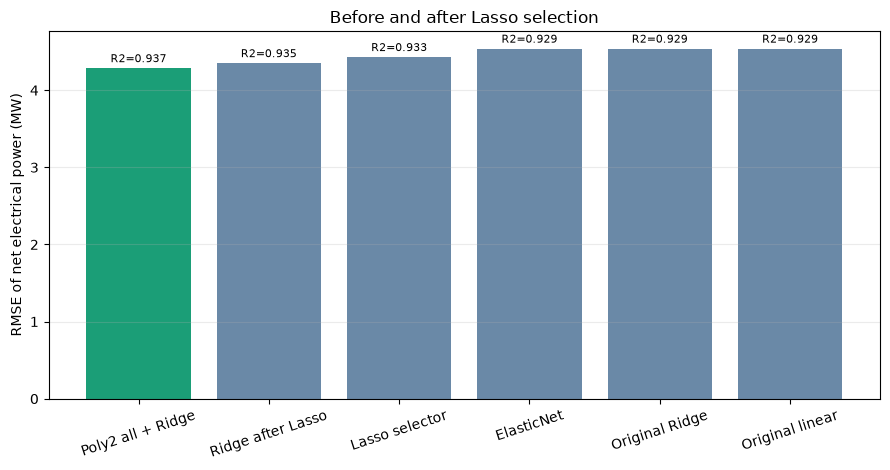

,model,RMSE,MAE,R2
0,Poly2 all + Ridge,4.283,3.344,0.937
1,Ridge after Lasso,4.348,3.437,0.935
2,Lasso selector,4.427,3.509,0.933
3,ElasticNet,4.537,3.586,0.929
4,Original Ridge,4.537,3.586,0.929
5,Original linear,4.537,3.586,0.929


In [6]:
fig, ax = plt.subplots(figsize=(9.0, 4.8))
colors = ["#1b9e77" if i == 0 else "#6a89a7" for i in range(len(metrics_ccpp))]
ax.bar(metrics_ccpp["model"], metrics_ccpp["RMSE"], color=colors)
ax.set_ylabel("RMSE of net electrical power (MW)")
ax.set_title("Before and after Lasso selection")
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", alpha=0.25)
for i, (_, row) in enumerate(metrics_ccpp.iterrows()):
    ax.text(i, row["RMSE"] + 0.08, f"R2={row["R2"]:.3f}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

display(metrics_ccpp.style.format({"RMSE": "{:.3f}", "MAE": "{:.3f}", "R2": "{:.3f}"}))

## Lasso selection after polynomial expansion

The plot below shows Lasso selecting linear, quadratic, and interaction terms for the chosen $\alpha$.

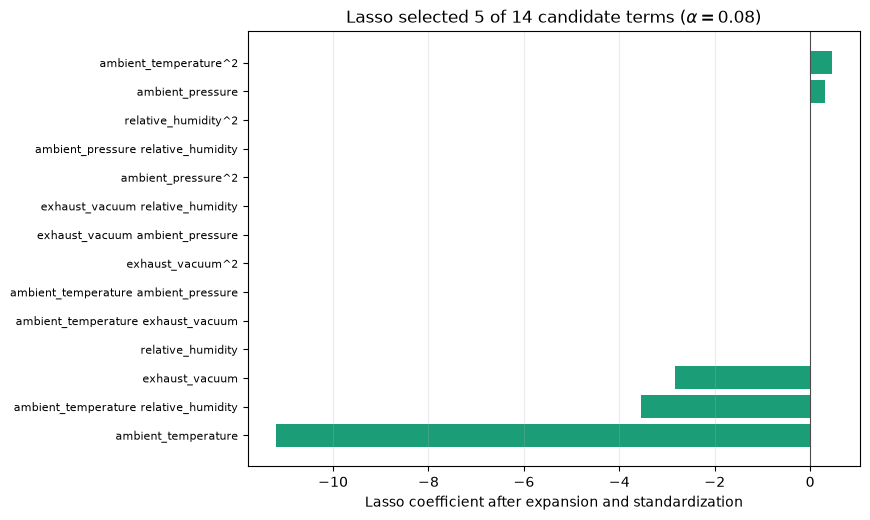

In [7]:
lasso_pipe = fitted_ccpp["Lasso selector"]
feature_names = lasso_pipe.named_steps["preprocess"].get_feature_names_out()
coef = lasso_pipe.named_steps["model"].coef_

coefs = (
    pd.DataFrame({"term": feature_names, "coefficient": coef})
    .assign(selected=lambda d: d["coefficient"].abs() > 1e-8)
    .sort_values("coefficient")
)
selected_count = int(coefs["selected"].sum())

y_pos = np.arange(len(coefs))
colors = np.where(coefs["selected"], "#1b9e77", "#c9c9c9")
fig, ax = plt.subplots(figsize=(8.8, 5.3))
ax.barh(y_pos, coefs["coefficient"], color=colors)
ax.set_yticks(y_pos)
ax.set_yticklabels(coefs["term"], fontsize=8)
ax.axvline(0, color="0.3", lw=0.8)
ax.set_xlabel("Lasso coefficient after expansion and standardization")
ax.set_title(
    f"Lasso selected {selected_count} of {len(coefs)} candidate terms "
    + rf"($\alpha={LASSO_SELECTION_ALPHA}$)"
)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(FIG_DIR / "lasso_variable_selection.png", dpi=180, bbox_inches="tight")
plt.show()

## Pointwise prediction on the test set

Zoom in on 120 test samples ordered by their original index. This is pointwise prediction: $PE(t)$ is estimated from the ambient/operating variables of observation $t$, not as a one-step-ahead forecast.

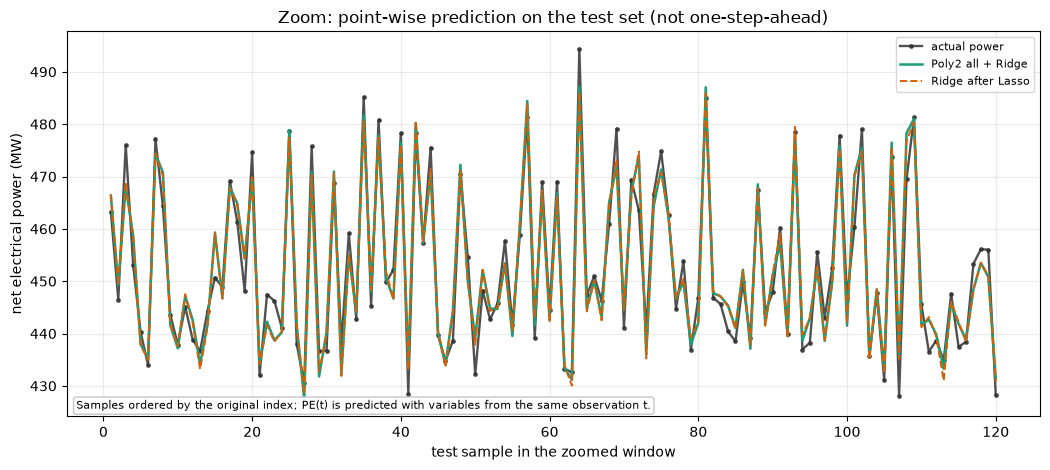

In [8]:
comparison = pd.DataFrame({
    "index": X_test.index.to_numpy(),
    "actual": y_test.to_numpy(),
    best_ccpp: fitted_ccpp[best_ccpp].predict(X_test),
    "Ridge after Lasso": fitted_ccpp["Ridge after Lasso"].predict(X_test),
}).sort_values("index")
zoom = comparison.head(120).copy()
zoom["zoom_sample"] = np.arange(1, len(zoom) + 1)

fig, ax = plt.subplots(figsize=(10.6, 4.8))
ax.plot(
    zoom["zoom_sample"],
    zoom["actual"],
    color="0.20",
    lw=1.7,
    marker="o",
    ms=2.4,
    alpha=0.85,
    label="actual power",
)
ax.plot(zoom["zoom_sample"], zoom[best_ccpp], color="#1b9e77", lw=1.8, label=best_ccpp)
ax.plot(
    zoom["zoom_sample"],
    zoom["Ridge after Lasso"],
    color="#d95f02",
    lw=1.4,
    linestyle="--",
    label="Ridge after Lasso",
)
ax.set_xlabel("test sample in the zoomed window")
ax.set_ylabel("net electrical power (MW)")
ax.set_title("Zoom: point-wise prediction on the test set (not one-step-ahead)")
ax.text(
    0.01,
    0.02,
    "Samples ordered by the original index; PE(t) is predicted with variables from the same observation t.",
    transform=ax.transAxes,
    fontsize=8,
    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.75", alpha=0.88),
)
ax.grid(alpha=0.25)
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "ccpp_temporal_prediction.png", dpi=180, bbox_inches="tight")
plt.show()

## Coefficient paths

For continuous variables, coefficients shrink as $\alpha$ increases. Ridge shrinks them smoothly; Lasso and Elastic Net may set some coefficients to zero.

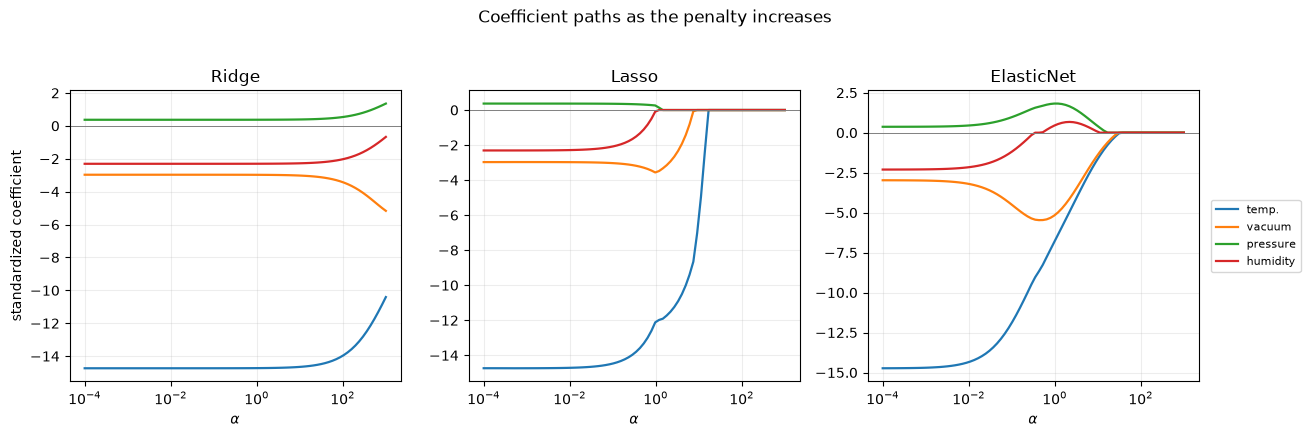

In [9]:
Xs = StandardScaler().fit_transform(power[continuous_cols])
y_all = power[target_col].to_numpy()
alphas = np.logspace(-4, 3, 80)
short_labels = ["temp.", "vacuum", "pressure", "humidity"]

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.2), sharex=True)
estimators = [
    ("Ridge", Ridge, {}),
    ("Lasso", Lasso, {"max_iter": 50000}),
    ("ElasticNet", ElasticNet, {"l1_ratio": 0.5, "max_iter": 50000}),
]
for ax, (title, cls, kwargs) in zip(axes, estimators):
    coefs_path = []
    for alpha in alphas:
        model = cls(alpha=alpha, **kwargs)
        model.fit(Xs, y_all)
        coefs_path.append(model.coef_)
    coefs_path = np.asarray(coefs_path)
    for j in range(coefs_path.shape[1]):
        ax.plot(alphas, coefs_path[:, j], lw=1.6, label=short_labels[j])
    ax.set_xscale("log")
    ax.axhline(0, color="0.5", lw=0.7)
    ax.set_title(title)
    ax.set_xlabel(r"$\alpha$")
    ax.grid(alpha=0.22)
axes[0].set_ylabel("standardized coefficient")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)
fig.suptitle("Coefficient paths as the penalty increases", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "coefficient_paths.png", dpi=180, bbox_inches="tight")
plt.show()

## More about `PolynomialFeatures`

Instead of changing the estimator, we transform the feature matrix:

$$
x=[x_1,x_2]\Rightarrow \phi_2(x)=[x_1,x_2,x_1^2,x_1x_2,x_2^2].
$$

Then we fit:

$$
\hat{y}=\beta_0+\phi_d(x)^\top\boldsymbol{\beta}.
$$

If $\phi_d(x)$ has $q$ features, the model remains linear in parameters $\beta_0,\ldots,\beta_q$. Nonlinearity comes from the transformed features.

## `PolynomialFeatures` with regularization

After transformation, the fitted model is:

$$
\hat{y}=\beta_0+\sum_{\ell=1}^{q}\beta_\ell z_\ell,
\qquad z=\phi_2(x).
$$

- $x$ denotes the original features; $z$ denotes the expanded features.
- For four continuous variables, degree 2 generates 14 terms: 4 linear, 4 quadratic, and 6 interaction terms.
- These terms are often correlated, so Ridge, Lasso, and Elastic Net help control variance.
- Regularization is almost essential as the degree increases because $q$ grows rapidly.

For example, a term such as $AT\cdot V$ allows the effect of ambient temperature to depend on exhaust vacuum; $AT^2$ allows a curved relationship with power.

In [10]:
poly = PolynomialFeatures(degree=2, include_bias=False)
poly.fit(power[continuous_cols])
poly_terms = poly.get_feature_names_out(continuous_cols)
print("Number of terms generated for four continuous variables and degree 2:", len(poly_terms))

Number of terms generated for four continuous variables and degree 2: 14


## Time series as supervised regression

$$
\hat{y}_{t+1}=f(y_t,y_{t-1},y_{t-2},y_{t-11},t,\sin(2\pi m/12),\cos(2\pi m/12)).
$$

- Lags represent system memory.
- A trend and sine/cosine terms represent gradual growth and annual seasonality.
- $t$ is the time index of the observation: in this example, the month number in the sequence.
- $m$ is the month of the year: $m=1$ for January, ..., $m=12$ for December.
- Validation must preserve time order: do not shuffle the training and test sets.

## Example: monthly airline passengers

`AirPassengers` series: monthly totals of international airline passengers, 1949–1960. Source: R `datasets::AirPassengers`.

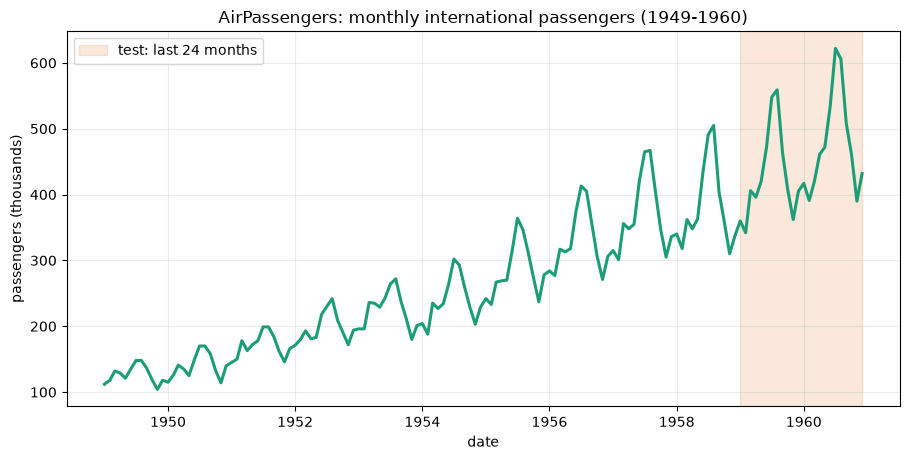

In [11]:
def load_airpassengers(path=AIRPASSENGERS_FILE):
    raw = pd.read_csv(path)
    dates = pd.date_range("1949-01-01", periods=len(raw), freq="MS")
    return pd.DataFrame({
        "date": dates,
        "month_index": np.arange(len(raw)),
        "month": dates.month,
        "passengers": raw["value"].astype(float),
    })


def make_airpassengers_supervised(df):
    data = df.copy()
    for lag in [1, 2, 3, 12]:
        data[f"lag_{lag}"] = data["passengers"].shift(lag)
    data["trend"] = data["month_index"]
    data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
    data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)
    return data.dropna().reset_index(drop=True)

air = load_airpassengers()

fig, ax = plt.subplots(figsize=(9.2, 4.7))
ax.plot(air["date"], air["passengers"], color="#1b9e77", lw=2.2)
ax.axvspan(
    air["date"].iloc[-24],
    air["date"].iloc[-1],
    color="#d95f02",
    alpha=0.14,
    label="test: last 24 months",
)
ax.set_title("AirPassengers: monthly international passengers (1949-1960)")
ax.set_xlabel("date")
ax.set_ylabel("passengers (thousands)")
ax.grid(alpha=0.25)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "airpassengers_series.png", dpi=180, bbox_inches="tight")
plt.show()

## One-step-ahead prediction

Each test month uses real lags already observed. This is one-step-ahead evaluation, not free-run simulation.

## Free-run prediction over the test horizon

After the first step, the model uses its own predictions to form new lags. Errors can propagate.

In [12]:
def fit_airpassengers_models(df):
    supervised = make_airpassengers_supervised(df)
    feature_cols_ts = ["lag_1", "lag_2", "lag_3", "lag_12", "trend", "month_sin", "month_cos"]
    target_col_ts = "passengers"
    train = supervised.iloc[:-24].copy()
    test = supervised.iloc[-24:].copy()
    X_train_ts = train[feature_cols_ts]
    y_train_ts = train[target_col_ts]
    X_test_ts = test[feature_cols_ts]
    y_test_ts = test[target_col_ts]
    cv = TimeSeriesSplit(n_splits=5)

    models = {
        "Original Ridge": GridSearchCV(
            Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
            {"model__alpha": np.logspace(-3, 3, 25)},
            cv=cv,
            scoring="neg_root_mean_squared_error",
        ),
        "Lasso selector": GridSearchCV(
            Pipeline([
                ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                ("scaler", StandardScaler()),
                ("model", Lasso(max_iter=100000, tol=1e-4)),
            ]),
            {"model__alpha": np.logspace(-4, 1, 25)},
            cv=cv,
            scoring="neg_root_mean_squared_error",
        ),
        "Ridge after Lasso": GridSearchCV(
            Pipeline([
                ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                ("scaler", StandardScaler()),
                (
                    "select",
                    SelectFromModel(
                        Lasso(alpha=0.1, max_iter=100000, tol=1e-4),
                        threshold=1e-8,
                    ),
                ),
                ("model", Ridge()),
            ]),
            {"model__alpha": np.logspace(-3, 3, 25)},
            cv=cv,
            scoring="neg_root_mean_squared_error",
        ),
        "Poly2 all + Ridge": GridSearchCV(
            Pipeline([
                ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                ("scaler", StandardScaler()),
                ("model", Ridge()),
            ]),
            {"model__alpha": np.logspace(-3, 3, 25)},
            cv=cv,
            scoring="neg_root_mean_squared_error",
        ),
    }
    order = ["Poly2 all + Ridge", "Ridge after Lasso", "Lasso selector", "Original Ridge"]

    fitted = {}
    rows_one_step = []
    predictions_one_step = {}
    for name, estimator in models.items():
        estimator.fit(X_train_ts, y_train_ts)
        pred = estimator.predict(X_test_ts)
        rows_one_step.append({
            "model": name,
            "RMSE": rmse(y_test_ts, pred),
            "MAE": float(mean_absolute_error(y_test_ts, pred)),
            "R2": float(r2_score(y_test_ts, pred)),
        })
        predictions_one_step[name] = pred
        fitted[name] = estimator

    rows_free = []
    predictions_free = {}
    for name in order:
        history = list(train[target_col_ts].to_numpy())
        preds = []
        for _, row in test.iterrows():
            x_next = pd.DataFrame([{
                "lag_1": history[-1],
                "lag_2": history[-2],
                "lag_3": history[-3],
                "lag_12": history[-12],
                "trend": row["trend"],
                "month_sin": row["month_sin"],
                "month_cos": row["month_cos"],
            }], columns=feature_cols_ts)
            y_hat = float(fitted[name].predict(x_next)[0])
            preds.append(y_hat)
            history.append(y_hat)
        pred = np.asarray(preds)
        predictions_free[name] = pred
        rows_free.append({
            "model": name,
            "RMSE": rmse(y_test_ts, pred),
            "MAE": float(mean_absolute_error(y_test_ts, pred)),
            "R2": float(r2_score(y_test_ts, pred)),
        })

    metrics_one_step = pd.DataFrame(rows_one_step).set_index("model").loc[order].reset_index()
    metrics_free = pd.DataFrame(rows_free).set_index("model").loc[order].reset_index()
    return {
        "train": train,
        "test": test,
        "y_test": y_test_ts,
        "fitted": fitted,
        "metrics_one_step": metrics_one_step,
        "metrics_free": metrics_free,
        "predictions_one_step": predictions_one_step,
        "predictions_free": predictions_free,
    }


ts = fit_airpassengers_models(air)


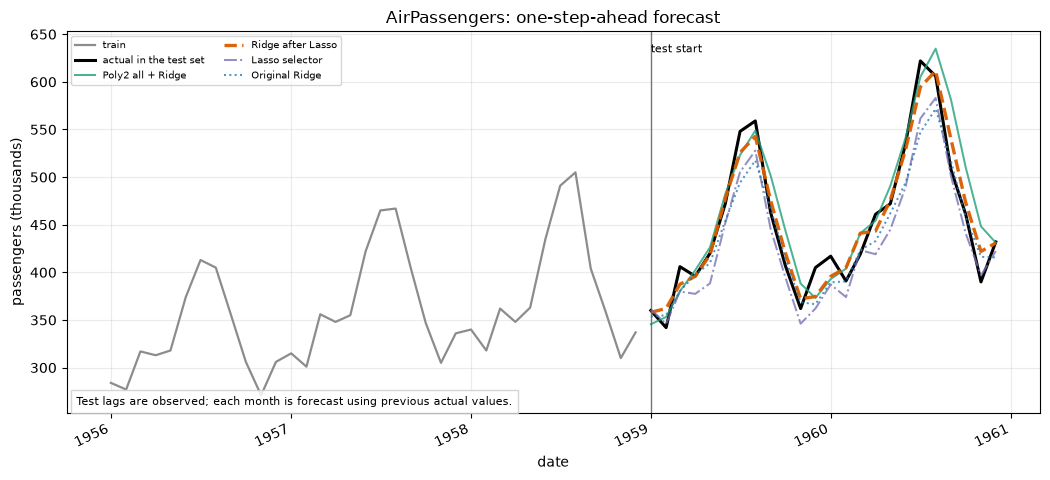

,model,RMSE,MAE,R2
0,Poly2 all + Ridge,29.238,23.400,0.847
1,Ridge after Lasso,17.547,14.509,0.945
2,Lasso selector,27.619,23.164,0.863
3,Original Ridge,27.902,20.888,0.860


In [13]:
def plot_air_forecast(predictions, metrics, filename, title, subtitle):
    train = ts["train"]
    test = ts["test"]
    y_test = ts["y_test"]
    best_name = metrics.sort_values("RMSE").iloc[0]["model"]
    styles = {
        "Poly2 all + Ridge": ("#1b9e77", "-"),
        "Ridge after Lasso": ("#d95f02", "--"),
        "Lasso selector": ("#7570b3", "-."),
        "Original Ridge": ("#1f78b4", ":"),
    }

    fig, ax = plt.subplots(figsize=(10.6, 4.9))
    ax.plot(train["date"].tail(36), train["passengers"].tail(36), color="0.55", lw=1.6, label="train")
    ax.plot(test["date"], y_test, color="black", lw=2.2, label="actual in the test set")
    for name in metrics["model"].tolist():
        color, linestyle = styles[name]
        lw = 2.4 if name == best_name else 1.45
        alpha = 0.96 if name == best_name else 0.78
        ax.plot(test["date"], predictions[name], color=color, lw=lw, linestyle=linestyle, alpha=alpha, label=name)
    ax.axvline(test["date"].iloc[0], color="0.35", lw=1.0, alpha=0.8)
    ax.text(test["date"].iloc[0], y_test.max() * 1.01, "test start", fontsize=8, ha="left", va="bottom")
    ax.set_title(title)
    ax.set_xlabel("date")
    ax.set_ylabel("passengers (thousands)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7, loc="upper left", ncol=2)
    ax.text(
        0.01,
        0.02,
        subtitle,
        transform=ax.transAxes,
        fontsize=8,
        bbox=dict(facecolor="white", alpha=0.82, edgecolor="0.8"),
    )
    fig.autofmt_xdate(rotation=25)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()

plot_air_forecast(
    ts["predictions_one_step"],
    ts["metrics_one_step"],
    "airpassengers_one_step.png",
    "AirPassengers: one-step-ahead forecast",
    "Test lags are observed; each month is forecast using previous actual values.",
)

display(ts["metrics_one_step"].style.format({"RMSE": "{:.3f}", "MAE": "{:.3f}", "R2": "{:.3f}"}))

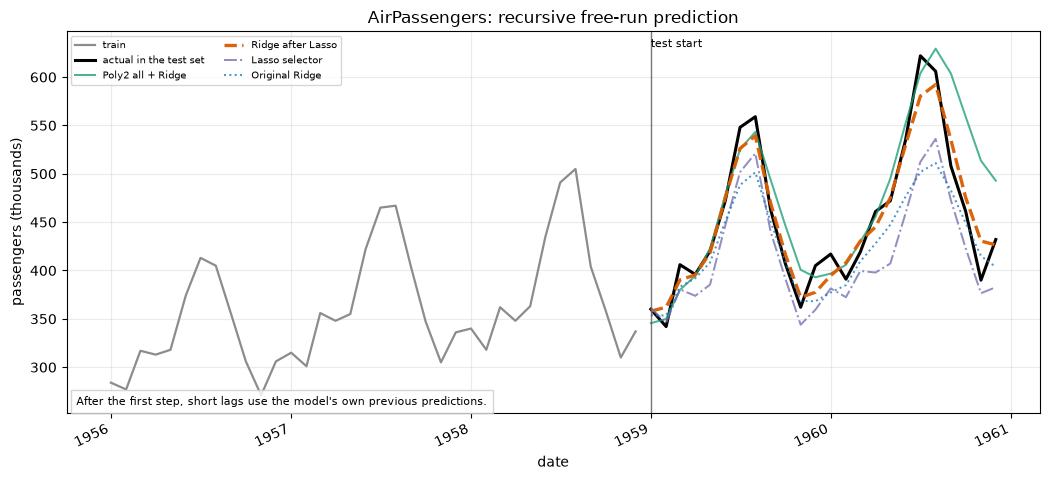

,model,RMSE,MAE,R2
0,Poly2 all + Ridge,43.829,30.378,0.656
1,Ridge after Lasso,18.555,14.864,0.938
2,Lasso selector,44.677,37.175,0.642
3,Original Ridge,41.943,30.426,0.685


In [14]:
plot_air_forecast(
    ts["predictions_free"],
    ts["metrics_free"],
    "airpassengers_free_run.png",
    "AirPassengers: recursive free-run prediction",
    "After the first step, short lags use the model's own previous predictions.",
)

display(ts["metrics_free"].style.format({"RMSE": "{:.3f}", "MAE": "{:.3f}", "R2": "{:.3f}"}))

## References

- GRUS, Joel. *Data Science do Zero: Noções Fundamentais com Python*. 2nd ed. Alta Books, 2020.
- TÜFEKCI, P. *Combined Cycle Power Plant* [Dataset]. UCI Machine Learning Repository, 2014. DOI: 10.24432/C5002N.
- PEDREGOSA, F. et al. *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, v. 12, p. 2825–2830, 2011.
- R CORE TEAM. `AirPassengers`: monthly airline passenger numbers 1949–1960. R `datasets` package. CSV via Rdatasets.